In [ ]:
import pandas as pd


In [ ]:
df = pd.read_csv("student_placement_prediction_dataset_2026.csv")

In [ ]:
df.head()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


In [ ]:
df.columns

Index(['student_id', 'age', 'gender', 'cgpa', 'branch', 'college_tier',
       'internships_count', 'projects_count', 'certifications_count',
       'coding_skill_score', 'aptitude_score', 'communication_skill_score',
       'logical_reasoning_score', 'hackathons_participated', 'github_repos',
       'linkedin_connections', 'mock_interview_score', 'attendance_percentage',
       'backlogs', 'extracurricular_score', 'leadership_score',
       'volunteer_experience', 'sleep_hours', 'study_hours_per_day',
       'placement_status', 'salary_package_lpa'],
      dtype='object')

In [ ]:
df.shape

(100000, 26)

In [ ]:
df.isnull().sum()

,0
student_id,0
age,0
gender,0
cgpa,0
branch,0
college_tier,0
internships_count,0
projects_count,0
certifications_count,0
coding_skill_score,0


In [ ]:
df['placement_status'].value_counts()

,count
placement_status,
Placed,54459
Not Placed,45541


In [ ]:
df['cgpa'].mean()

np.float64(7.4968902)

In [ ]:
df.groupby('placement_status')['cgpa'].mean()

,cgpa
placement_status,
Not Placed,7.483789
Placed,7.507846


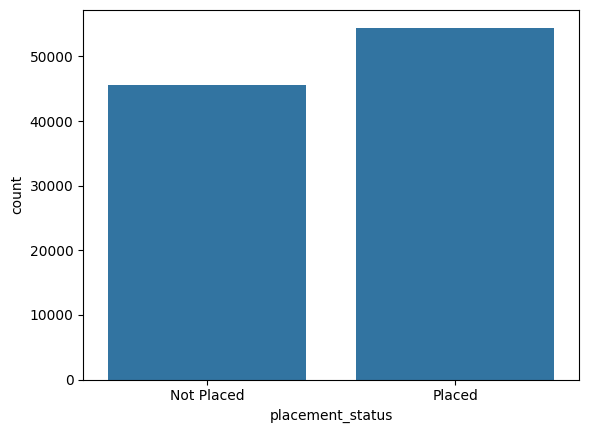

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='placement_status',data=df)
plt.show()

In [ ]:
df.groupby('placement_status')['internshios_count'].mean()

,internships_count
placement_status,
Not Placed,1.417163
Placed,1.573367


In [ ]:
df.groupby('placement_status')['projects_count'].mean()

,projects_count
placement_status,
Not Placed,2.886410
Placed,3.098404


In [ ]:
df.groupby('placement_status')['coding_skill_score'].mean()

<bound method GroupBy.mean of <pandas.core.groupby.generic.SeriesGroupBy object at 0x7b0a97116690>>

In [ ]:
df.groupby('placement_status')['mock_interview_score'].mean()

,mock_interview_score
placement_status,
Not Placed,69.388182
Placed,70.492185


In [ ]:
import os

os.listdir()

['.config', 'student_placement_prediction_dataset_2026.csv', 'sample_data']

In [ ]:
import pandas as pd

df = pd.read_csv('student_placement_prediction_dataset_2026.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   student_id                 100000 non-null  int64  
 1   age                        100000 non-null  int64  
 2   gender                     100000 non-null  object 
 3   cgpa                       100000 non-null  float64
 4   branch                     100000 non-null  object 
 5   college_tier               100000 non-null  object 
 6   internships_count          100000 non-null  int64  
 7   projects_count             100000 non-null  int64  
 8   certifications_count       100000 non-null  int64  
 9   coding_skill_score         100000 non-null  float64
 10  aptitude_score             100000 non-null  float64
 11  communication_skill_score  100000 non-null  float64
 12  logical_reasoning_score    100000 non-null  float64
 13  hackathons_participated    100

In [ ]:
df['placement_status'] = df['placement_status'].map({
    'placed':1,
    'not placed':0
})

In [ ]:
df['placement_status'].head()

,placement_status
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN


In [ ]:
df = pd.get_dummies(df,
                    columns=[
                        'gender',
                        'branch',
                        'college_tier',
                        'volunteer_experience'
                    ],
                    drop_first=True)

In [ ]:
x = df.drop(['placement_status'],axis=1)

y = df['placement_status']

In [ ]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# 1. Reload the dataset to get original placement_status values
df = pd.read_csv('student_placement_prediction_dataset_2026.csv')

# 2. Map correctly using matching capitalization ('Placed' / 'Not Placed')
df['placement_status'] = df['placement_status'].map({
    'Placed': 1,
    'Not Placed': 0
})

# 3. Apply dummy encoding
df = pd.get_dummies(df,
                    columns=[
                        'gender',
                        'branch',
                        'college_tier',
                        'volunteer_experience'
                    ],
                    drop_first=True)

# 4. Separate features and target
x = df.drop(['placement_status'], axis=1)
y = df['placement_status']

# 5. Split dataset
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

# 6. Initialize and fit the Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)
print("Model trained successfully!")

Model trained successfully!


Accuracy Score: 100.0000%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9127
           1       1.00      1.00      1.00     10873

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



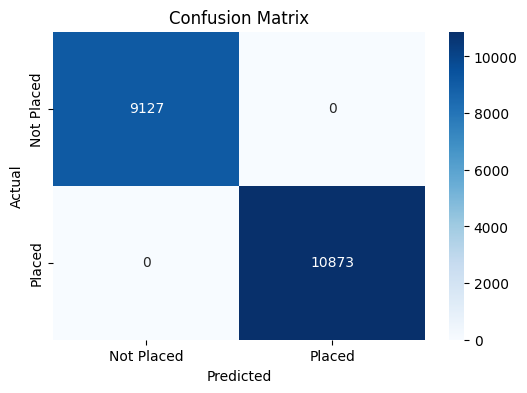

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Make predictions on the test set
y_pred = model.predict(x_test)

# Calculate and print metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Placed', 'Placed'], yticklabels=['Not Placed', 'Placed'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

1.0

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9127
           1       1.00      1.00      1.00     10873

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



In [ ]:
importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': model.coef_[0]
})

importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

,Feature,Importance
20,salary_package_lpa,2.308756
4,projects_count,0.029745
16,extracurricular_score,0.026557
3,internships_count,0.021402
7,aptitude_score,0.021276
8,communication_skill_score,0.009259
13,mock_interview_score,0.001529
22,branch_Civil,0.000248
28,college_tier_Tier 3,0.000139
0,student_id,-0.000002


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(x_train, y_train)

pred = rf.predict(x_test)

accuracy_score(y_test, pred)

1.0

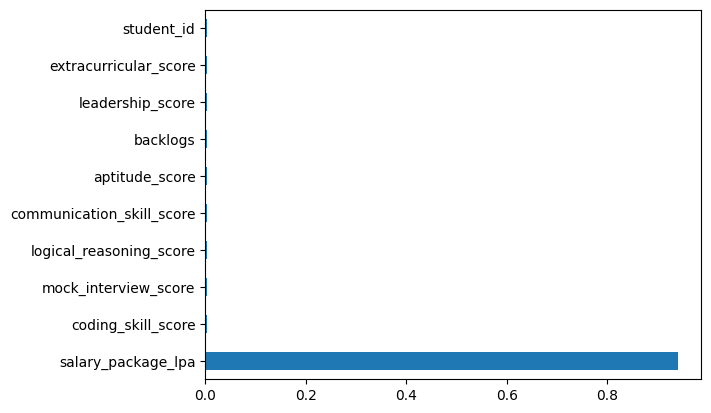

In [ ]:
import matplotlib.pyplot as plt

feature_imp = pd.Series(
    rf.feature_importances_,
    index=x.columns
)

feature_imp.sort_values(
    ascending=False
).head(10).plot(
    kind='barh'
)

plt.show()

In [ ]:
X = df.drop('placement_status', axis=1)
y = df['placement_status']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9127
           1       1.00      1.00      1.00     10873

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
rf_pred = rf.predict(X_test)

In [ ]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 1.0


In [ ]:
import pandas as pd

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.head(10))

                      Feature  Importance
20         salary_package_lpa    0.939427
6          coding_skill_score    0.004341
13       mock_interview_score    0.004171
9     logical_reasoning_score    0.003778
8   communication_skill_score    0.003622
7              aptitude_score    0.003613
15                   backlogs    0.003378
17           leadership_score    0.003373
16      extracurricular_score    0.003319
0                  student_id    0.003264


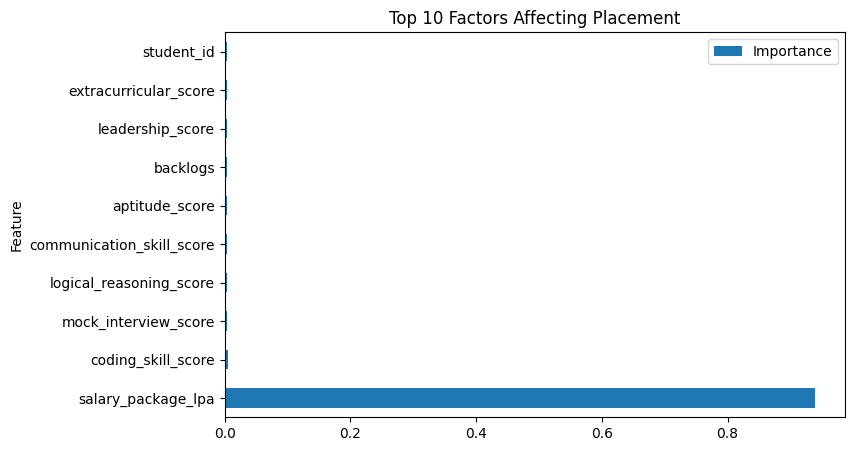

In [ ]:
import matplotlib.pyplot as plt

importance.head(10).plot(
    x='Feature',
    y='Importance',
    kind='barh',
    figsize=(8,5)
)

plt.title("Top 10 Factors Affecting Placement")
plt.show()

In [ ]:
import os

os.listdir()

['.config',
 '.ipynb_checkpoints',
 'Student_Placement_Prediction.ipynb.ipynb',
 'student_placement_prediction_dataset_2026.csv',
 'sample_data']

In [ ]:
import os

os.path.exists("Student_Placement_Prediction.ipynb.ipynb")

True

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("student_placement_prediction_dataset_2026.csv")

In [ ]:
df.head()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


In [ ]:
df.shape

(100000, 26)

In [ ]:
df.columns

Index(['student_id', 'age', 'gender', 'cgpa', 'branch', 'college_tier',
       'internships_count', 'projects_count', 'certifications_count',
       'coding_skill_score', 'aptitude_score', 'communication_skill_score',
       'logical_reasoning_score', 'hackathons_participated', 'github_repos',
       'linkedin_connections', 'mock_interview_score', 'attendance_percentage',
       'backlogs', 'extracurricular_score', 'leadership_score',
       'volunteer_experience', 'sleep_hours', 'study_hours_per_day',
       'placement_status', 'salary_package_lpa'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
student_id,0
age,0
gender,0
cgpa,0
branch,0
college_tier,0
internships_count,0
projects_count,0
certifications_count,0
coding_skill_score,0


In [ ]:
df['placement_status'].unique()

array(['Not Placed', 'Placed'], dtype=object)

In [ ]:
df['placement_status'].value_counts()

,count
placement_status,
Placed,54459
Not Placed,45541


In [ ]:
x = df.drop(['placement_status'],axis=1)

x.head()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,...,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,...,184,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,...,539,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,...,568,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,...,550,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,...,833,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,12.16


In [ ]:
y = df['placement_status']

y.head()

,placement_status
0,Not Placed
1,Not Placed
2,Placed
3,Not Placed
4,Placed


In [ ]:
print("Features:",x.shape)
print("Target:",y.shape)

Features: (100000, 25)
Target: (100000,)


In [ ]:
# Input features
X = df.drop(
    ['placement_status', 'student_id', 'salary_package_lpa'],
    axis=1
)

# Target
y = df['placement_status']

In [ ]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (100000, 23)
Target: (100000,)


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (80000, 23)
X_test: (20000, 23)
y_train: (80000,)
y_test: (20000,)


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model = LogisticRegression(max_iter=1000)

In [ ]:
print(model)

LogisticRegression(max_iter=1000)


In [ ]:
# One-hot encode the categorical variables first
X_encoded = pd.get_dummies(X, columns=['gender', 'branch', 'college_tier', 'volunteer_experience'], drop_first=True)

# Split the encoded features
X_train_enc, X_test_enc, y_train_enc, y_test_enc = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Fit the model
model.fit(X_train_enc, y_train_enc)

# Now we can view the classes
model.classes_

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


array(['Not Placed', 'Placed'], dtype=object)

In [ ]:
model.classes_

array(['Not Placed', 'Placed'], dtype=object)

In [ ]:
model.fit(X_train_enc, y_train_enc)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [ ]:
model.fit(X_train_enc, y_train_enc)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [ ]:
print(X_train_enc.shape)
print(y_train_enc.shape)

print(X_train_enc.dtypes)
print(y_train_enc.value_counts(dropna=False))

(80000, 28)
(80000,)
age                            int64
cgpa                         float64
internships_count              int64
projects_count                 int64
certifications_count           int64
coding_skill_score           float64
aptitude_score               float64
communication_skill_score    float64
logical_reasoning_score      float64
hackathons_participated        int64
github_repos                   int64
linkedin_connections           int64
mock_interview_score         float64
attendance_percentage        float64
backlogs                       int64
extracurricular_score        float64
leadership_score             float64
sleep_hours                  float64
study_hours_per_day          float64
gender_Male                     bool
branch_Civil                    bool
branch_ECE                      bool
branch_EEE                      bool
branch_IT                       bool
branch_Mechanical               bool
college_tier_Tier 2             bool
college_tier_Tier

In [ ]:
print("Missing values in X:", X_train_enc.isnull().sum().sum())
print("Missing values in y:", y_train_enc.isnull().sum())

Missing values in X: 0
Missing values in y: 0


In [ ]:
print("X shape:", X_train_enc.shape)
print("y shape:", y_train_enc.shape)

print("X data types:")
print(X_train_enc.dtypes)

print("Target values:")
print(y_train_enc.value_counts())

X shape: (80000, 28)
y shape: (80000,)
X data types:
age                            int64
cgpa                         float64
internships_count              int64
projects_count                 int64
certifications_count           int64
coding_skill_score           float64
aptitude_score               float64
communication_skill_score    float64
logical_reasoning_score      float64
hackathons_participated        int64
github_repos                   int64
linkedin_connections           int64
mock_interview_score         float64
attendance_percentage        float64
backlogs                       int64
extracurricular_score        float64
leadership_score             float64
sleep_hours                  float64
study_hours_per_day          float64
gender_Male                     bool
branch_Civil                    bool
branch_ECE                      bool
branch_EEE                      bool
branch_IT                       bool
branch_Mechanical               bool
college_tier_Tier 2   

In [ ]:
model.fit(X_train_enc, y_train_enc)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_enc, y_train_enc)

print("Model trained successfully!")

Model trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
y_pred = model.predict(X_test_enc)

print(y_pred[:10])

['Not Placed' 'Not Placed' 'Placed' 'Not Placed' 'Placed' 'Placed'
 'Placed' 'Placed' 'Placed' 'Placed']


In [ ]:
print(type(y_pred))
print(y_pred[:10])
print(len(y_pred))

<class 'numpy.ndarray'>
['Not Placed' 'Not Placed' 'Placed' 'Not Placed' 'Placed' 'Placed'
 'Placed' 'Placed' 'Placed' 'Placed']
20000


In [ ]:
print(y_pred[:10])

['Not Placed' 'Not Placed' 'Placed' 'Not Placed' 'Placed' 'Placed'
 'Placed' 'Placed' 'Placed' 'Placed']


In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test_enc[:10].values,
    'Predicted': y_pred[:10]
})

print(comparison)

       Actual   Predicted
0  Not Placed  Not Placed
1  Not Placed  Not Placed
2  Not Placed      Placed
3      Placed  Not Placed
4      Placed      Placed
5  Not Placed      Placed
6      Placed      Placed
7      Placed      Placed
8  Not Placed      Placed
9  Not Placed      Placed


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test_enc, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 56.79 %


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_enc, y_pred)

print(cm)

[[2810 6298]
 [2344 8548]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test_enc, y_pred))

              precision    recall  f1-score   support

  Not Placed       0.55      0.31      0.39      9108
      Placed       0.58      0.78      0.66     10892

    accuracy                           0.57     20000
   macro avg       0.56      0.55      0.53     20000
weighted avg       0.56      0.57      0.54     20000



In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_enc, y_train_enc)

baseline_pred = baseline.predict(X_test_enc)

baseline_accuracy = accuracy_score(y_test_enc, baseline_pred)

print("Baseline Accuracy:", baseline_accuracy * 100, "%")
print("Logistic Regression Accuracy:", accuracy * 100, "%")

Baseline Accuracy: 54.459999999999994 %
Logistic Regression Accuracy: 56.79 %


In [ ]:
print("Training features:")
print(X_train_enc.columns.tolist())

print("\nNumber of training features:")
print(X_train_enc.shape[1])

print("\nMissing values:")
print(X_train_enc.isnull().sum().sum())

Training features:
['age', 'cgpa', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'sleep_hours', 'study_hours_per_day', 'gender_Male', 'branch_Civil', 'branch_ECE', 'branch_EEE', 'branch_IT', 'branch_Mechanical', 'college_tier_Tier 2', 'college_tier_Tier 3', 'volunteer_experience_Yes']

Number of training features:
28

Missing values:
0


In [ ]:
print(X_train_enc.describe().T[['mean', 'std', 'min', 'max']])

                                 mean         std   min    max
age                         21.006775    1.999376  18.0   24.0
cgpa                         7.496115    0.993567   4.5   10.0
internships_count            1.502263    1.221838   0.0    8.0
projects_count               3.002325    1.730204   0.0   13.0
certifications_count         2.007363    1.418374   0.0   11.0
coding_skill_score          69.810836   14.665967  20.0  100.0
aptitude_score              64.982385   14.858377  20.0  100.0
communication_skill_score   67.963314   13.852905  20.0  100.0
logical_reasoning_score     65.957953   14.833177  20.0  100.0
hackathons_participated      1.000975    0.997227   0.0    8.0
github_repos                 4.010525    2.009133   0.0   16.0
linkedin_connections       524.960150  274.974448  50.0  999.0
mock_interview_score        69.982542   11.935296  20.0  100.0
attendance_percentage       84.723687    9.418805  50.0  100.0
backlogs                     0.497088    0.708941   0.0

In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns
numeric_cols = X_train_enc.select_dtypes(include=['number']).columns

# Make copies of training and testing data
X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()

# Create the scaler
scaler = StandardScaler()

# Learn scaling values from training data
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_enc[numeric_cols]
)

# Apply the same scaling to testing data
X_test_scaled[numeric_cols] = scaler.transform(
    X_test_enc[numeric_cols]
)

print("Feature scaling completed!")
print(X_train_scaled[numeric_cols].head())

Feature scaling completed!
            age      cgpa  internships_count  projects_count  \
12685 -0.003389  0.970132           0.407370        0.576626   
72956 -1.003707  1.332465          -1.229518        0.576626   
75845  0.996930 -1.032766          -1.229518       -0.001344   
83333  0.496771  0.265595          -1.229518        0.576626   
76658 -1.003707  2.016872           2.862703       -0.001344   

       certifications_count  coding_skill_score  aptitude_score  \
12685             -0.005191           -0.134162        1.052074   
72956              1.404884            0.396304        0.804193   
75845              0.699846            0.055630       -0.409284   
83333              0.699846            0.036316       -1.761297   
76658             -1.415265           -1.455508        0.688710   

       communication_skill_score  logical_reasoning_score  \
12685                   0.249635                -0.168017   
72956                   0.069629                -0.375126   
75

In [ ]:
from sklearn.linear_model import LogisticRegression

model_scaled = LogisticRegression(max_iter=1000)

model_scaled.fit(X_train_scaled, y_train_enc)

print("Scaled model trained successfully!")

Scaled model trained successfully!


In [ ]:
from sklearn.metrics import accuracy_score

y_pred_scaled = model_scaled.predict(X_test_scaled)

scaled_accuracy = accuracy_score(y_test_enc, y_pred_scaled)

print("Old Accuracy:", accuracy * 100, "%")
print("New Accuracy:", scaled_accuracy * 100, "%")

Old Accuracy: 56.79 %
New Accuracy: 56.98 %


In [ ]:
from sklearn.metrics import accuracy_score

y_pred_scaled = model_scaled.predict(X_test_scaled)

scaled_accuracy = accuracy_score(y_test_enc, y_pred_scaled)

print("Old Accuracy:", accuracy * 100, "%")
print("New Accuracy:", scaled_accuracy * 100, "%")

Old Accuracy: 56.79 %
New Accuracy: 56.98 %


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test_enc, y_pred_scaled))

              precision    recall  f1-score   support

  Not Placed       0.55      0.33      0.41      9108
      Placed       0.58      0.77      0.66     10892

    accuracy                           0.57     20000
   macro avg       0.56      0.55      0.54     20000
weighted avg       0.56      0.57      0.55     20000



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_enc, y_train_enc)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
rf_pred = rf_model.predict(X_test_enc)

In [ ]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test_enc, rf_pred)

print("Logistic Regression:", scaled_accuracy * 100, "%")
print("Random Forest:", rf_accuracy * 100, "%")

Logistic Regression: 56.98 %
Random Forest: 55.169999999999995 %


In [ ]:
import pandas as pd

importance = pd.DataFrame({
    'Feature': X_train_enc.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.head(10))

                      Feature  Importance
12       mock_interview_score    0.066924
5          coding_skill_score    0.066712
6              aptitude_score    0.066156
8     logical_reasoning_score    0.065936
7   communication_skill_score    0.065568
16           leadership_score    0.064978
15      extracurricular_score    0.063718
11       linkedin_connections    0.063491
1                        cgpa    0.062877
13      attendance_percentage    0.061835


In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_test_enc,
    y_test_enc,
    n_repeats=3,
    random_state=42,
    scoring='balanced_accuracy',
    n_jobs=-1
)

permutation_results = pd.DataFrame({
    'Feature': X_test_enc.columns,
    'Importance': perm.importances_mean
})

permutation_results = permutation_results.sort_values(
    by='Importance',
    ascending=False
)

print(permutation_results.head(10))

                     Feature  Importance
14                  backlogs    0.011775
2          internships_count    0.011757
3             projects_count    0.006243
5         coding_skill_score    0.005819
12      mock_interview_score    0.002184
8    logical_reasoning_score    0.001828
18       study_hours_per_day    0.001814
16          leadership_score    0.001758
27  volunteer_experience_Yes    0.001482
15     extracurricular_score    0.001263


In [ ]:
from sklearn.metrics import balanced_accuracy_score

lr_balanced = balanced_accuracy_score(
    y_test_enc, y_pred_scaled
)

rf_balanced = balanced_accuracy_score(
    y_test_enc, rf_pred
)

print("Logistic Regression:", lr_balanced * 100, "%")
print("Random Forest:", rf_balanced * 100, "%")

Logistic Regression: 54.99760010489864 %
Random Forest: 53.62895428280473 %


In [ ]:
print(df['placement_status'].value_counts())

print("\nPlacement status percentages:")
print(
    df['placement_status']
    .value_counts(normalize=True) * 100
)

placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64

Placement status percentages:
placement_status
Placed        54.459
Not Placed    45.541
Name: proportion, dtype: float64


In [ ]:
print(
    df.groupby('placement_status')[
        ['cgpa', 'internships_count',
         'projects_count', 'coding_skill_score',
         'aptitude_score', 'backlogs']
    ].mean().round(2)
)

                  cgpa  internships_count  projects_count  coding_skill_score  \
placement_status                                                                
Not Placed        7.48               1.42            2.89               69.01   
Placed            7.51               1.57            3.10               70.51   

                  aptitude_score  backlogs  
placement_status                            
Not Placed                 64.47      0.56  
Placed                     65.42      0.44  


In [ ]:
import os
os.listdir()

['.config', 'student_placement_prediction_dataset_2026.csv', 'sample_data']

In [ ]:
import pandas as pd

# Load the dataset to define 'df'
df = pd.read_csv('student_placement_prediction_dataset_2026.csv')

# Calculate and print the mean backlogs grouped by placement status
print(df.groupby('placement_status')['backlogs'].mean())

placement_status
Not Placed    0.561428
Placed        0.444206
Name: backlogs, dtype: float64


In [ ]:
backlog_table = pd.crosstab(
    df['backlogs'],
    df['placement_status'],
    normalize='index'
) * 100

print(backlog_table.round(2))

placement_status  Not Placed  Placed
backlogs                            
0                      42.77   57.23
1                      47.99   52.01
2                      55.20   44.80
3                      60.23   39.77
4                      64.64   35.36
5                      66.67   33.33
6                     100.00    0.00


In [ ]:
print(df['backlogs'].value_counts().sort_index())

backlogs
0    60884
1    30177
2     7458
3     1280
4      181
5       18
6        2
Name: count, dtype: int64


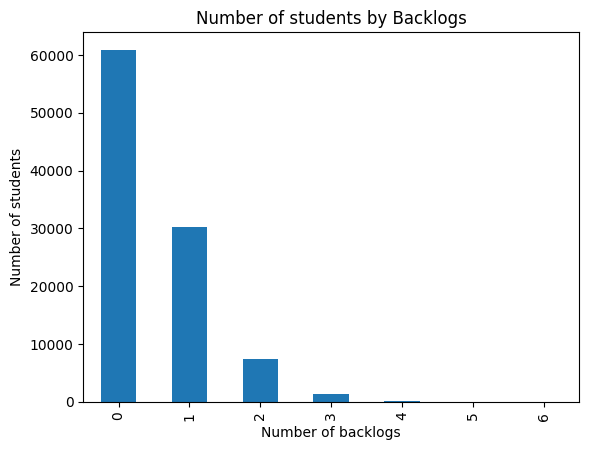

In [ ]:
import matplotlib.pyplot as plt

df['backlogs'].value_counts().sort_index().plot(
    kind='bar',
    title='Number of students by Backlogs'

)

plt.xlabel('Number of backlogs')
plt.ylabel('Number of students')
plt.show()

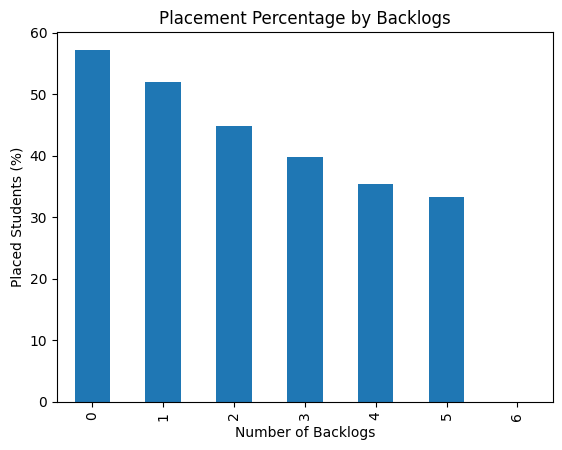

In [ ]:
import matplotlib.pyplot as plt

df.groupby('backlogs')['placement_status'].apply(
    lambda x: (x == 'Placed').mean() * 100
).plot(kind='bar', title='Placement Percentage by Backlogs')

plt.xlabel('Number of Backlogs')
plt.ylabel('Placed Students (%)')
plt.show()

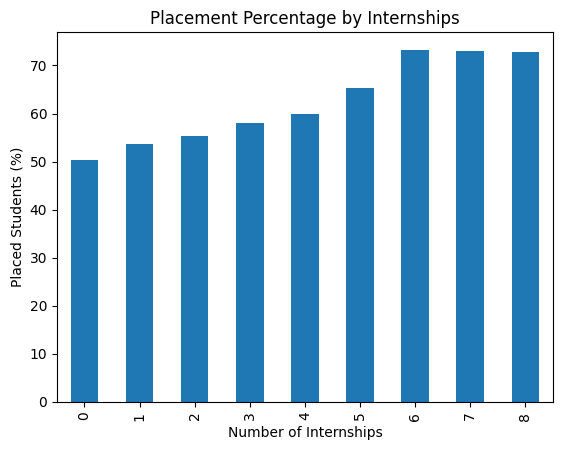

In [12]:
df.groupby('internships_count')['placement_status'].apply(
    lambda x: (x == 'Placed').mean() * 100
).plot(kind='bar', title='Placement Percentage by Internships')

plt.xlabel('Number of Internships')
plt.ylabel('Placed Students (%)')
plt.show()


In [13]:
summary = df.groupby('internships_count')['placement_status'].apply(
    lambda x: (x == 'placed').mean()*100

).reset_index(name='Placement_Percentage')

print(summary)

   internships_count  Placement_Percentage
0                  0                   0.0
1                  1                   0.0
2                  2                   0.0
3                  3                   0.0
4                  4                   0.0
5                  5                   0.0
6                  6                   0.0
7                  7                   0.0
8                  8                   0.0


In [14]:
print(df['placement_status'].unique())
print(df['placement_status'].value_counts())

['Not Placed' 'Placed']
placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64


In [15]:
summary = df.groupby('internships_count').apply(
    lambda group: (group['placement_status'] == 'Placed').sum()
    / len(group) * 100
).reset_index(name='Placement_Percentage')

print(summary)

   internships_count  Placement_Percentage
0                  0             50.317525
1                  1             53.702379
2                  2             55.399753
3                  3             57.951204
4                  4             59.944218
5                  5             65.368852
6                  6             73.255814
7                  7             72.972973
8                  8             72.727273


/tmp/ipykernel_844/2104326482.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = df.groupby('internships_count').apply(


In [16]:
print(df['internships_count'].value_counts().sort_index())

internships_count
0    22203
1    33546
2    25103
3    12583
4     4661
5     1464
6      344
7       74
8       22
Name: count, dtype: int64


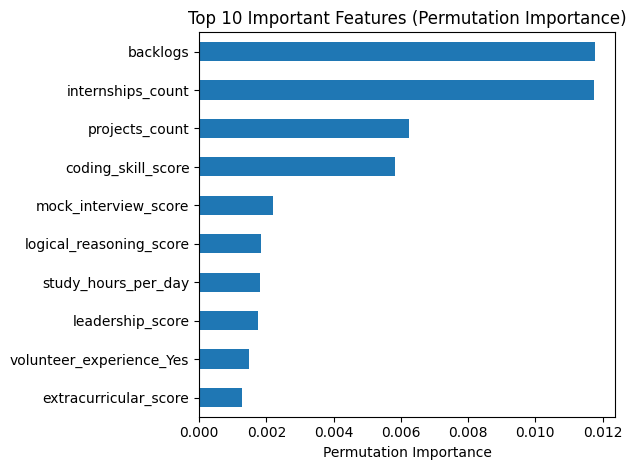

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# 1. Load the dataset
df = pd.read_csv('student_placement_prediction_dataset_2026.csv')

# 2. Preprocess target and features
df['placement_status'] = df['placement_status'].map({
    'Placed': 1,
    'Not Placed': 0
})

X = df.drop(['placement_status', 'student_id', 'salary_package_lpa'], axis=1)
y = df['placement_status']

# 3. One-hot encode categorical features
X_encoded = pd.get_dummies(X, columns=['gender', 'branch', 'college_tier', 'volunteer_experience'], drop_first=True)

# 4. Train-Test Split
X_train_enc, X_test_enc, y_train_enc, y_test_enc = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Initialize and Train the Random Forest Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_enc, y_train_enc)

# 6. Calculate Permutation Importance
result = permutation_importance(
    rf_model,
    X_test_enc,
    y_test_enc,
    n_repeats=3,
    random_state=42,
    scoring='balanced_accuracy',
    n_jobs=-1
)

importance = pd.Series(
    result.importances_mean,
    index=X_test_enc.columns
).sort_values(ascending=False)

# 7. Plot top 10 features
importance.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Important Features (Permutation Importance)')
plt.xlabel('Permutation Importance')
plt.tight_layout()
plt.show()

In [6]:
print("Training features:", X_train_enc.shape)
print("Testing features:", X_test_enc.shape)

print("Same columns:",
      list(X_train_enc.columns) == list(X_test_enc.columns))

Training features: (80000, 28)
Testing features: (20000, 28)
Same columns: True


In [7]:
print("Salary package included:",
      'salary_package_lpa' in X_train_enc.columns)

print("Student ID included:",
      'student_id' in X_train_enc.columns)

print("Placement status included:",
      'placement_status' in X_train_enc.columns)

Salary package included: False
Student ID included: False
Placement status included: False


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
print(df[['age', 'cgpa', 'backlogs',
          'internships_count',
          'attendance_percentage']].describe())

                 age           cgpa       backlogs  internships_count  \
count  100000.000000  100000.000000  100000.000000       100000.00000   
mean       21.005740       7.496890       0.497590            1.50223   
std         1.999562       0.992834       0.708434            1.22528   
min        18.000000       4.500000       0.000000            0.00000   
25%        19.000000       6.820000       0.000000            1.00000   
50%        21.000000       7.500000       0.000000            1.00000   
75%        23.000000       8.180000       1.000000            2.00000   
max        24.000000      10.000000       6.000000            8.00000   

       attendance_percentage  
count          100000.000000  
mean               84.730169  
std                 9.416075  
min                50.000000  
25%                78.325833  
50%                85.018828  
75%                91.782511  
max               100.000000  


In [10]:
print("Branches:")
print(df['branch'].value_counts())

print("\nCollege tiers:")
print(df['college_tier'].value_counts())

print("\nGender:")
print(df['gender'].value_counts())

Branches:
branch
CSE           34818
IT            19999
ECE           14908
EEE           10177
Mechanical    10077
Civil         10021
Name: count, dtype: int64

College tiers:
college_tier
Tier 2    49955
Tier 3    29884
Tier 1    20161
Name: count, dtype: int64

Gender:
gender
Male      60028
Female    39972
Name: count, dtype: int64


In [12]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Standardize numerical columns
numeric_cols = X_train_enc.select_dtypes(include=['number']).columns

X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()

scaler = StandardScaler()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train_enc[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test_enc[numeric_cols])

# 2. Re-train the Logistic Regression model
model_scaled = LogisticRegression(max_iter=1000)
model_scaled.fit(X_train_scaled, y_train_enc)

# 3. Predict and compute accuracies
train_pred = model_scaled.predict(X_train_scaled)
test_pred = model_scaled.predict(X_test_scaled)

print("Training Accuracy:", accuracy_score(y_train_enc, train_pred) * 100)
print("Testing Accuracy:", accuracy_score(y_test_enc, test_pred) * 100)

Training Accuracy: 57.02125
Testing Accuracy: 56.98


In [13]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_enc, y_train_enc)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [14]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

gb_pred = gb_model.predict(X_test_enc)

print("Accuracy:",
      accuracy_score(y_test_enc, gb_pred) * 100)

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test_enc, gb_pred) * 100)

Accuracy: 56.645
Balanced Accuracy: 54.34745715146967


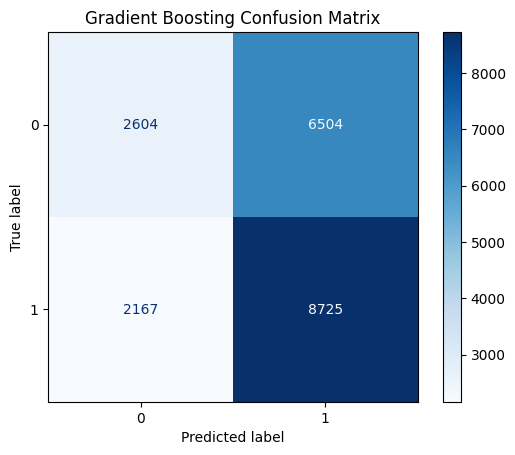

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_enc, gb_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=gb_model.classes_
)

display.plot(cmap='Blues')
plt.title('Gradient Boosting Confusion Matrix')
plt.show()

In [16]:
print("Model classes:", gb_model.classes_)

Model classes: [0 1]


In [18]:
print(pd.crosstab(
    pd.Series(y_train_enc).reset_index(drop=True),
    pd.Series(y_train_enc).reset_index(drop=True)
))

placement_status      0      1
placement_status              
0                 36433      0
1                     0  43567


In [19]:
print(pd.crosstab(
    y_train_enc,
    df.loc[y_train_enc.index, 'placement_status']
))

placement_status      0      1
placement_status              
0                 36433      0
1                     0  43567


In [20]:
df['placement_status'] = df['placement_status'].map({
    'Not Placed': 0,
    'Placed': 1
})

In [21]:
print(df['placement_status'].value_counts())

Series([], Name: count, dtype: int64)


In [22]:
print("DataFrame shape:", df.shape)
print("Missing target values:", df['placement_status'].isna().sum())
print("Encoded target values:")
print(y_train_enc.value_counts())

DataFrame shape: (100000, 26)
Missing target values: 100000
Encoded target values:
placement_status
1    43567
0    36433
Name: count, dtype: int64


In [23]:
print(df.head())
print(df['placement_status'].isna().sum())

   student_id  age  gender  cgpa branch college_tier  internships_count  \
0           1   24    Male  7.53     IT       Tier 2                  4   
1           2   21    Male  7.92    CSE       Tier 2                  1   
2           3   22  Female  8.60    EEE       Tier 1                  0   
3           4   24    Male  6.68    CSE       Tier 1                  0   
4           5   20  Female  8.43     IT       Tier 3                  1   

   projects_count  certifications_count  coding_skill_score  ...  \
0               6                     1           99.238568  ...   
1               3                     6           80.966123  ...   
2               1                     1           49.177184  ...   
3               2                     2           79.359084  ...   
4               4                     3           65.018573  ...   

   mock_interview_score  attendance_percentage  backlogs  \
0             72.647009              77.463863         2   
1             61.699

In [24]:
df_original = pd.read_csv(
    "student_placement_prediction_dataset_2026.csv"
)

print(df_original['placement_status'].value_counts())

placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64


In [25]:
df_original['placement_status_encoded'] = (
    df_original['placement_status'].map({
        'Not Placed': 0,
        'Placed': 1
    })
)

print(pd.crosstab(
    df_original['placement_status'],
    df_original['placement_status_encoded']
))

placement_status_encoded      0      1
placement_status                      
Not Placed                45541      0
Placed                        0  54459


In [26]:
df = df_original.copy()

print(df['placement_status'].value_counts())
print("Missing values:",
      df['placement_status'].isnull().sum())

placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64
Missing values: 0


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score

lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

lr_balanced.fit(X_train_scaled, y_train_enc)

balanced_pred = lr_balanced.predict(X_test_scaled)

print("Accuracy:",
      accuracy_score(y_test_enc, balanced_pred) * 100)

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test_enc, balanced_pred) * 100)

Accuracy: 55.785
Balanced Accuracy: 55.68528577218641


In [29]:
from sklearn.metrics import classification_report

print("ORIGINAL LOGISTIC REGRESSION")
print(classification_report(y_test_enc, test_pred))

print("\nBALANCED LOGISTIC REGRESSION")
print(classification_report(y_test_enc, balanced_pred))

ORIGINAL LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.55      0.33      0.41      9108
           1       0.58      0.77      0.66     10892

    accuracy                           0.57     20000
   macro avg       0.56      0.55      0.54     20000
weighted avg       0.56      0.57      0.55     20000


BALANCED LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.51      0.55      0.53      9108
           1       0.60      0.57      0.58     10892

    accuracy                           0.56     20000
   macro avg       0.56      0.56      0.56     20000
weighted avg       0.56      0.56      0.56     20000



In [30]:
from sklearn.metrics import roc_auc_score

original_prob = model_scaled.predict_proba(X_test_scaled)[:, 1]

balanced_prob = lr_balanced.predict_proba(X_test_scaled)[:, 1]

print("Original ROC-AUC:",
      roc_auc_score(y_test_enc, original_prob))

print("Balanced ROC-AUC:",
      roc_auc_score(y_test_enc, balanced_prob))

Original ROC-AUC: 0.5849712556918883
Balanced ROC-AUC: 0.5849534036496147


In [31]:
print("Model:", model_scaled)
print("Scaler:", scaler)

print("Training features:", X_train_scaled.shape)
print("Testing features:", X_test_scaled.shape)

print("Model classes:", model_scaled.classes_)

print("Feature columns match:",
      list(X_train_scaled.columns) == list(X_test_scaled.columns))

Model: LogisticRegression(max_iter=1000)
Scaler: StandardScaler()
Training features: (80000, 28)
Testing features: (20000, 28)
Model classes: [0 1]
Feature columns match: True


In [32]:
import joblib

# Save model and preprocessing information together
model_package = {
    "model": model_scaled,
    "scaler": scaler,
    "feature_columns": list(X_train_scaled.columns),
    "numeric_columns": list(numeric_cols),
    "target_mapping": {
        "Not Placed": 0,
        "Placed": 1
    }
}

# Save the complete package
joblib.dump(model_package, "student_placement_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [33]:
from google.colab import files

files.download("student_placement_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import joblib

# Load the saved model package
loaded_package = joblib.load("student_placement_model.joblib")

# Extract model and preprocessing objects
loaded_model = loaded_package["model"]
loaded_scaler = loaded_package["scaler"]
loaded_columns = loaded_package["feature_columns"]
loaded_numeric_columns = loaded_package["numeric_columns"]

print("Saved model loaded successfully!")
print("Model:", loaded_model)
print("Scaler:", loaded_scaler)
print("Number of features:", len(loaded_columns))

Saved model loaded successfully!
Model: LogisticRegression(max_iter=1000)
Scaler: StandardScaler()
Number of features: 28


In [35]:
# Predict using the loaded model
test_prediction = loaded_model.predict(X_test_scaled)

print("Predictions:", test_prediction[:10])
print("Test accuracy:", loaded_model.score(X_test_scaled, y_test_enc))

Predictions: [0 0 1 0 1 1 1 1 1 1]
Test accuracy: 0.5698


In [36]:
# Identify the original input features
feature_cols = [
    col for col in df.columns
    if col not in [
        'student_id',
        'salary_package_lpa',
        'placement_status'
    ]
]

print("Total input features:", len(feature_cols))

print("\nInput feature names:")
print(feature_cols)

print("\nCategorical columns and their accepted values:")

categorical_cols = df[feature_cols].select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:
    print(col, ":", df[col].unique())

Total input features: 24

Input feature names:
['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day', 'placement_status_encoded']

Categorical columns and their accepted values:
gender : ['Male' 'Female']
branch : ['IT' 'CSE' 'EEE' 'Civil' 'Mechanical' 'ECE']
college_tier : ['Tier 2' 'Tier 1' 'Tier 3']
volunteer_experience : ['Yes' 'No']


In [37]:
feature_cols = [
    col for col in df.columns
    if col not in [
        'student_id',
        'salary_package_lpa',
        'placement_status',
        'placement_status_encoded'
    ]
]

print("Total input features:", len(feature_cols))
print(feature_cols)

Total input features: 23
['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day']


In [38]:
print("Model expects:", len(loaded_columns), "encoded features")
print("\nExpected encoded columns:")

for col in loaded_columns:
    print(col)

Model expects: 28 encoded features

Expected encoded columns:
age
cgpa
internships_count
projects_count
certifications_count
coding_skill_score
aptitude_score
communication_skill_score
logical_reasoning_score
hackathons_participated
github_repos
linkedin_connections
mock_interview_score
attendance_percentage
backlogs
extracurricular_score
leadership_score
sleep_hours
study_hours_per_day
gender_Male
branch_Civil
branch_ECE
branch_EEE
branch_IT
branch_Mechanical
college_tier_Tier 2
college_tier_Tier 3
volunteer_experience_Yes


In [39]:
import pandas as pd

# Define the original categorical categories and their order
category_options = {
    'gender': ['Female', 'Male'],
    'branch': ['CSE', 'Civil', 'ECE', 'EEE', 'IT', 'Mechanical'],
    'college_tier': ['Tier 1', 'Tier 2', 'Tier 3'],
    'volunteer_experience': ['No', 'Yes']
}

def predict_student_placement(student_details):

    # Convert student details into a DataFrame
    new_student = pd.DataFrame([student_details])

    # Validate categorical values
    for col, categories in category_options.items():
        if student_details[col] not in categories:
            raise ValueError(
                f"Invalid {col}. Choose from: {categories}"
            )

        new_student[col] = pd.Categorical(
            new_student[col],
            categories=categories
        )

    # Apply the same one-hot encoding
    new_student_encoded = pd.get_dummies(
        new_student,
        columns=list(category_options.keys()),
        drop_first=True
    )

    # Match the exact 28 training columns
    new_student_encoded = new_student_encoded.reindex(
        columns=loaded_columns,
        fill_value=0
    )

    # Scale the same numerical columns
    new_student_scaled = new_student_encoded.copy()

    new_student_scaled[loaded_numeric_columns] = (
        loaded_scaler.transform(
            new_student_encoded[loaded_numeric_columns]
        )
    )

    # Predict placement
    prediction = loaded_model.predict(new_student_scaled)[0]

    probability = loaded_model.predict_proba(
        new_student_scaled
    )[0]

    result = 'Placed' if prediction == 1 else 'Not Placed'

    print("Predicted Placement:", result)
    print("Probability of Not Placed:", round(probability[0] * 100, 2), "%")
    print("Probability of Placed:", round(probability[1] * 100, 2), "%")

    return result

In [40]:
# Take one student's original details for testing
sample_student = df[feature_cols].iloc[0].to_dict()

# Make prediction
predict_student_placement(sample_student)

Predicted Placement: Placed
Probability of Not Placed: 36.63 %
Probability of Placed: 63.37 %


'Placed'

In [41]:
new_student = {
    'age': 22,
    'gender': 'Male',
    'cgpa': 8.5,
    'branch': 'CSE',
    'college_tier': 'Tier 1',
    'internships_count': 2,
    'projects_count': 3,
    'certifications_count': 2,
    'coding_skill_score': 85,
    'aptitude_score': 80,
    'communication_skill_score': 75,
    'logical_reasoning_score': 82,
    'hackathons_participated': 2,
    'github_repos': 5,
    'linkedin_connections': 300,
    'mock_interview_score': 80,
    'attendance_percentage': 90,
    'backlogs': 0,
    'extracurricular_score': 75,
    'leadership_score': 80,
    'volunteer_experience': 'Yes',
    'sleep_hours': 7,
    'study_hours_per_day': 5
}

predict_student_placement(new_student)

Predicted Placement: Placed
Probability of Not Placed: 29.92 %
Probability of Placed: 70.08 %


'Placed'